# CICIDS2017 : modélisation et comparaison
**Licence 3 TCO, ASJA Antsirabe** — suite des notebooks NSL-KDD et « chargement/nettoyage ».

Entrée : `data/processed/cicids2017_clean.parquet` (produit par le notebook 02). Sorties : `models/ids_model.joblib` et `models/ids_family_model.joblib`.

On compare **deux protocoles d'évaluation** :
- **A. Découpage aléatoire stratifié** (70 % / 30 %) : le plus simple, mais **optimiste**, car train et test contiennent les mêmes types d'attaques et des flux très proches ;
- **B. Découpage par jour** : entraînement lundi → jeudi, test **vendredi**. Le vendredi contient Bot, PortScan et DDoS, absents des jours précédents : c'est un test de **généralisation à des attaques inconnues**, plus proche de la réalité.

L'écart entre A et B est probablement **le résultat le plus intéressant de ton mémoire**.

## 0. Imports et configuration

In [1]:
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.model_selection import train_test_split
from sklearn.metrics import (precision_score, recall_score, f1_score, accuracy_score, confusion_matrix,
                             ConfusionMatrixDisplay, average_precision_score, precision_recall_curve)
warnings.filterwarnings("ignore")
SEED = 42

DATA_FILE = os.environ.get("CICIDS_CLEAN", "../data/processed/cicids2017_clean.parquet")   # ou ../data/processed/cicids2017_sample.parquet pour tester vite
PER_CLASS_TRAIN_CAP = 100_000   # plafond par classe dans le TRAIN (None = tout garder, plus lent)

## 1. Chargement

In [2]:
df = pd.read_parquet(DATA_FILE)
meta = ["Label", "source_file", "is_attack", "family"]
FEATS = [c for c in df.columns if c not in meta]
print(df.shape, "|", len(FEATS), "caractéristiques")
pd.crosstab(df["Label"], df["source_file"])

(2498078, 67) | 63 caractéristiques


source_file,Friday,Monday,Thursday,Tuesday,Wednesday
Label,,,,,
BENIGN,394731,492670,394756,397325,392855
Bot,1948,0,0,0,0
DDoS,128014,0,0,0,0
DoS GoldenEye,0,0,0,0,10286
DoS Hulk,0,0,0,0,172846
DoS Slowhttptest,0,0,0,0,5228
DoS slowloris,0,0,0,0,5385
FTP-Patator,0,0,0,5931,0
Heartbleed,0,0,0,0,11


Le tableau ci-dessus montre **quel jour contient quelle attaque** : c'est la base du protocole B.
Lundi = trafic normal uniquement ; mardi = brute force ; mercredi = DoS ; jeudi = attaques web et infiltration ; vendredi = botnet, PortScan, DDoS.

## 2. Outils communs
Un seul jeu de fonctions pour entraîner et évaluer les 4 modèles sur n'importe quel découpage.

In [3]:
def cap_per_class(d, cap):
    if cap is None: return d
    return pd.concat([g.sample(min(len(g), cap), random_state=SEED) for _, g in d.groupby("Label")])

def make_models():
    return {
        "Régression logistique": make_pipeline(StandardScaler(),
            LogisticRegression(max_iter=300, class_weight="balanced", random_state=SEED)),
        "Arbre de décision": DecisionTreeClassifier(max_depth=20, class_weight="balanced", random_state=SEED),
        "Random Forest": RandomForestClassifier(n_estimators=100, class_weight="balanced_subsample",
                                                n_jobs=-1, random_state=SEED),
    }

def run_protocol(tr, te, feats, tag):
    """Entraîne les 4 modèles sur `tr`, évalue sur `te`. Renvoie (résultats, prédictions, scores, modèles)."""
    tr = cap_per_class(tr, PER_CLASS_TRAIN_CAP)
    Xtr, ytr = tr[feats].to_numpy("float32"), tr["is_attack"].to_numpy()
    Xte, yte = te[feats].to_numpy("float32"), te["is_attack"].to_numpy()
    print(f"[{tag}] train={len(tr):,} ({ytr.mean():.1%} attaques) | test={len(te):,} ({yte.mean():.1%} attaques)")
    res, preds, scores, fitted = [], {}, {}, {}

    def score_it(name, y_pred, y_score, t_fit, t_pred):
        tn, fp, fn, tp = confusion_matrix(yte, y_pred, labels=[0, 1]).ravel()
        res.append(dict(protocole=tag, modele=name,
            precision=precision_score(yte, y_pred, zero_division=0), rappel=recall_score(yte, y_pred),
            f1=f1_score(yte, y_pred), pr_auc=average_precision_score(yte, y_score),
            faux_positifs=fp, faux_negatifs=fn, t_fit_s=t_fit, t_pred_s=t_pred))
        preds[name], scores[name] = y_pred, y_score

    for name, m in make_models().items():
        t0 = time.time(); m.fit(Xtr, ytr); t_fit = time.time() - t0
        t0 = time.time(); proba = m.predict_proba(Xte)[:, 1]; t_pred = time.time() - t0
        score_it(name, (proba >= 0.5).astype(int), proba, t_fit, t_pred)
        fitted[name] = m

    # Isolation Forest : entraîné UNIQUEMENT sur du trafic normal
    sc = StandardScaler().fit(Xtr[ytr == 0])
    iso = IsolationForest(n_estimators=200, contamination=0.02, random_state=SEED, n_jobs=-1)
    t0 = time.time(); iso.fit(sc.transform(Xtr[ytr == 0])); t_fit = time.time() - t0
    t0 = time.time(); Z = sc.transform(Xte); an = -iso.score_samples(Z); y_pred = (iso.predict(Z) == -1).astype(int)
    t_pred = time.time() - t0
    score_it("Isolation Forest", y_pred, an, t_fit, t_pred)
    fitted["Isolation Forest"] = (sc, iso)
    return res, preds, scores, fitted

def recall_by_label(te, y_pred):
    """Part de chaque type d'attaque correctement détectée."""
    t = te.assign(pred=y_pred)
    t = t[t.is_attack == 1]
    return t.groupby("Label").apply(lambda g: (g.pred == 1).mean()).sort_values()

## 3. Protocole A : découpage aléatoire stratifié

In [4]:
trA, teA = train_test_split(df, test_size=0.30, stratify=df["Label"], random_state=SEED)
resA, predsA, scoresA, modelsA = run_protocol(trA, teA, FEATS, "A : aléatoire")
pd.DataFrame(resA).set_index("modele").drop(columns="protocole").round(4)

[A : aléatoire] train=377,027 (73.5% attaques) | test=749,424 (17.0% attaques)


,precision,rappel,f1,pr_auc,faux_positifs,faux_negatifs,t_fit_s,t_pred_s
modele,,,,,,,,
Régression logistique,0.7320,0.9734,0.8356,0.9387,45526,3401,12.4274,0.2707
Arbre de décision,0.9903,0.9995,0.9949,0.9912,1250,65,10.1987,0.0885
Random Forest,0.9925,0.9994,0.9959,0.9972,970,81,39.5116,3.1178
Isolation Forest,0.7995,0.3750,0.5105,0.5109,12011,79829,1.9270,13.0223


## 4. Protocole B : entraînement lundi–jeudi, test vendredi

In [5]:
TRAIN_DAYS = ["Monday", "Tuesday", "Wednesday", "Thursday"]
TEST_DAYS = ["Friday"]
trB, teB = df[df.source_file.isin(TRAIN_DAYS)], df[df.source_file.isin(TEST_DAYS)]

unseen = sorted(set(teB.Label) - set(trB.Label))
print("Attaques du test ABSENTES de l'entraînement :", unseen)
resB, predsB, scoresB, modelsB = run_protocol(trB, teB, FEATS, "B : par jour")
pd.DataFrame(resB).set_index("modele").drop(columns="protocole").round(4)

Attaques du test ABSENTES de l'entraînement : ['Bot', 'DDoS', 'PortScan']


[B : par jour] train=232,239 (56.9% attaques) | test=615,387 (35.9% attaques)


,precision,rappel,f1,pr_auc,faux_positifs,faux_negatifs,t_fit_s,t_pred_s
modele,,,,,,,,
Régression logistique,0.9012,0.6008,0.7209,0.7837,14530,88096,9.7334,0.2477
Arbre de décision,0.9646,0.5307,0.6847,0.6803,4292,103561,6.9105,0.0613
Random Forest,0.9939,0.3708,0.5402,0.7680,499,138826,23.5867,1.7680
Isolation Forest,0.5705,0.0975,0.1666,0.4832,16200,199136,3.5664,9.0908


## 5. A contre B
La chute du **rappel** entre A et B mesure la perte de performance face à des attaques jamais vues.

In [6]:
allres = pd.DataFrame(resA + resB)
cmp = allres.pivot(index="modele", columns="protocole", values=["f1", "rappel", "precision"]).round(3)
cmp

f1                     rappel               \
protocole             A : aléatoire B : par jour A : aléatoire B : par jour   
modele                                                                        
Arbre de décision             0.995        0.685         0.999        0.531   
Isolation Forest              0.511        0.167         0.375        0.098   
Random Forest                 0.996        0.540         0.999        0.371   
Régression logistique         0.836        0.721         0.973        0.601   

                          precision               
protocole             A : aléatoire B : par jour  
modele                                            
Arbre de décision             0.990        0.965  
Isolation Forest              0.799        0.571  
Random Forest                 0.992        0.994  
Régression logistique         0.732        0.901

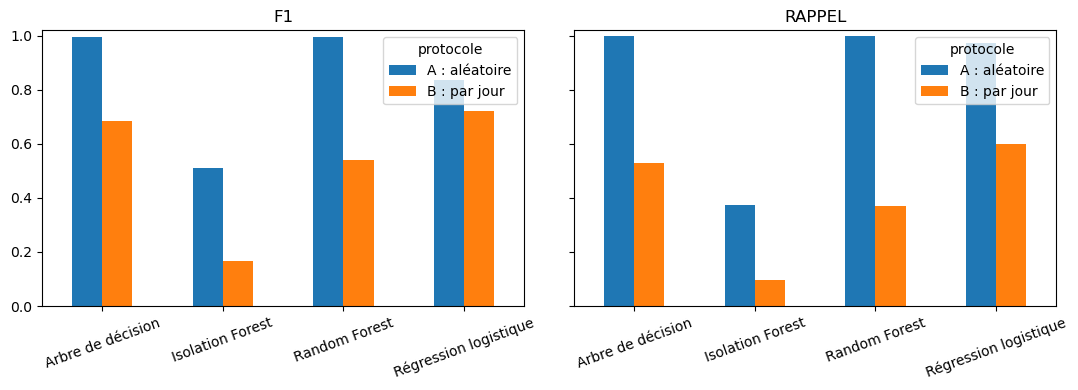

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, met in zip(axes, ["f1", "rappel"]):
    allres.pivot(index="modele", columns="protocole", values=met).plot.bar(ax=ax, rot=20)
    ax.set_title(met.upper()); ax.set_xlabel(""); ax.set_ylim(0, 1.02)
plt.tight_layout(); plt.show()

## 6. Quelles attaques échappent aux modèles ?
Le **rappel par type d'attaque** (Random Forest). En protocole B, les attaques inconnues devraient apparaître en tête des échecs.

In [8]:
for tag, te, pr in [("A", teA, predsA), ("B", teB, predsB)]:
    print(f"--- Protocole {tag} : rappel par attaque (Random Forest) ---")
    print(recall_by_label(te, pr["Random Forest"]).round(3).to_string())
    print()

--- Protocole A : rappel par attaque (Random Forest) ---
Label
Infiltration                      0.545
Web Attack - - - Sql Injection    0.833
Bot                               0.961
Web Attack - - - XSS              0.990
Web Attack - - - Brute Force      0.998
PortScan                          0.999
DoS GoldenEye                     0.999
DoS slowloris                     0.999
DoS Hulk                          1.000
DDoS                              1.000
DoS Slowhttptest                  1.000
FTP-Patator                       1.000
Heartbleed                        1.000
SSH-Patator                       1.000

--- Protocole B : rappel par attaque (Random Forest) ---


Label
Bot         0.000
PortScan    0.006
DDoS        0.635



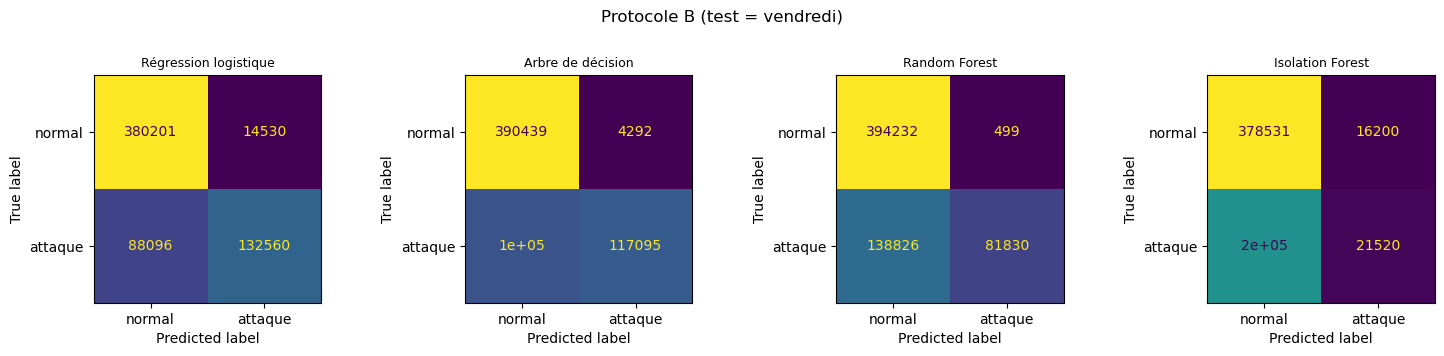

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.4))
for a, (name, y_pred) in zip(axes, predsB.items()):
    ConfusionMatrixDisplay(confusion_matrix(teB.is_attack, y_pred, labels=[0, 1]),
                           display_labels=["normal", "attaque"]).plot(ax=a, colorbar=False)
    a.set_title(name, fontsize=9)
plt.suptitle("Protocole B (test = vendredi)", y=1.02); plt.tight_layout(); plt.show()

## 7. Expérience de robustesse : retirer `Destination Port`
Certaines attaques utilisent des ports typiques (21 = FTP-Patator, 22 = SSH-Patator, 80 = DoS/Web). Un modèle peut alors **apprendre le port plutôt que le comportement**.
On réentraîne le Random Forest **sans** cette variable : si les scores chutent, le modèle s'appuyait dessus.

In [10]:
if "Destination Port" in FEATS:
    feats_np = [f for f in FEATS if f != "Destination Port"]
    rows = []
    for tag, tr, te in [("A : aléatoire", trA, teA), ("B : par jour", trB, teB)]:
        tr_ = cap_per_class(tr, PER_CLASS_TRAIN_CAP)
        for nom, f in [("avec port", FEATS), ("sans port", feats_np)]:
            rf = RandomForestClassifier(n_estimators=100, class_weight="balanced_subsample", n_jobs=-1, random_state=SEED)
            rf.fit(tr_[f].to_numpy("float32"), tr_.is_attack)
            p = rf.predict(te[f].to_numpy("float32"))
            rows.append(dict(protocole=tag, variante=nom, precision=precision_score(te.is_attack, p, zero_division=0),
                             rappel=recall_score(te.is_attack, p), f1=f1_score(te.is_attack, p)))
    display(pd.DataFrame(rows).round(3))
else:
    print("Destination Port absent des données.")

,protocole,variante,precision,rappel,f1
0,A : aléatoire,avec port,0.993,0.999,0.996
1,A : aléatoire,sans port,0.987,0.999,0.993
2,B : par jour,avec port,0.994,0.371,0.540
3,B : par jour,sans port,0.991,0.370,0.539


## 8. Compromis précision / rappel
Un IDS réel ne coupe pas à 0,5 : on choisit un **seuil** selon le coût d'une fausse alerte contre celui d'une attaque ratée.

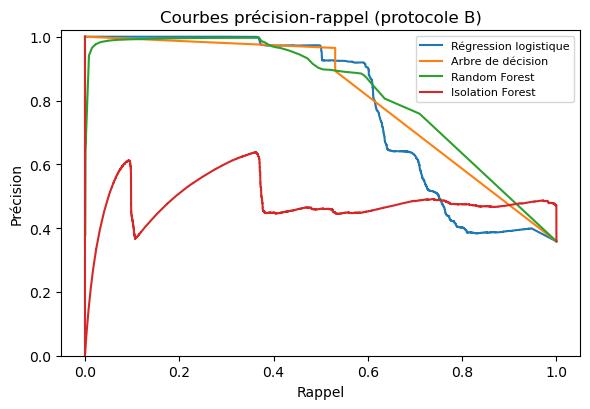

In [11]:
fig, ax = plt.subplots(figsize=(6, 4.2))
for name, s in scoresB.items():
    p, r, _ = precision_recall_curve(teB.is_attack, s)
    ax.plot(r, p, label=name)
ax.set_xlabel("Rappel"); ax.set_ylabel("Précision"); ax.set_title("Courbes précision-rappel (protocole B)")
ax.legend(fontsize=8); ax.set_ylim(0, 1.02); plt.tight_layout(); plt.show()

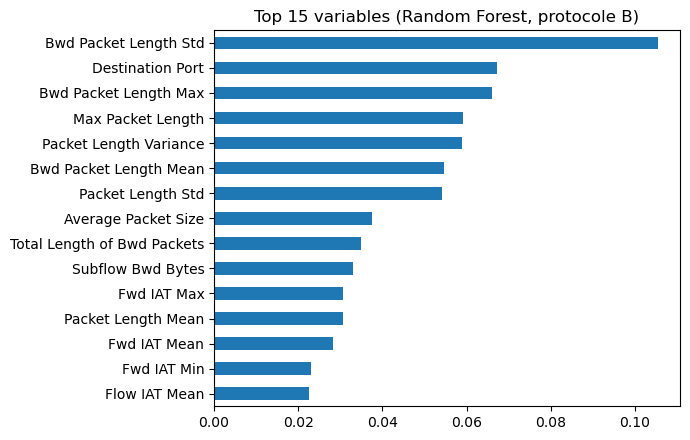

In [12]:
imp = pd.Series(modelsB["Random Forest"].feature_importances_, index=FEATS).sort_values(ascending=False).head(15)
imp.iloc[::-1].plot.barh(figsize=(7, 4.5), title="Top 15 variables (Random Forest, protocole B)")
plt.tight_layout(); plt.show()

## 9. Type d'attaque probable : modèle multiclasse (2e étage)
Le modèle binaire dit **« suspect »**, pas **« quelle attaque »**. On ajoute un second modèle, entraîné **uniquement sur les attaques**, qui prédit leur **famille** (DoS/DDoS, PortScan, BruteForce, WebAttack, Botnet, Infiltration).

Fonctionnement en chaîne :
1. le modèle binaire détecte les flux suspects ;
2. le modèle multiclasse nomme la famille **des flux suspects seulement**.

> **Limite à assumer devant le jury** : ce modèle ne connaît que les familles vues à l'entraînement. Face à une attaque inédite, il choisira la famille connue la plus proche. On gère cela avec un **seuil de confiance** : sous ce seuil, le verdict est « indéterminée ».

In [13]:
from sklearn.metrics import classification_report
att = df[df.is_attack == 1]
print(att.family.value_counts().to_string())

trF, teF = train_test_split(att, test_size=0.30, stratify=att["family"], random_state=SEED)
trF = pd.concat([g.sample(min(len(g), PER_CLASS_TRAIN_CAP or len(g)), random_state=SEED) for _, g in trF.groupby("family")])

rfF = RandomForestClassifier(n_estimators=200, class_weight="balanced_subsample", n_jobs=-1, random_state=SEED)
rfF.fit(trF[FEATS].to_numpy("float32"), trF["family"])
pF = rfF.predict(teF[FEATS].to_numpy("float32"))
print()
print(classification_report(teF["family"], pF, zero_division=0))

family
DoS/DDoS        321770
PortScan         90694
BruteForce        9150
WebAttack         2143
Botnet            1948
Infiltration        36


              precision    recall  f1-score   support

      Botnet       1.00      1.00      1.00       584
  BruteForce       1.00      1.00      1.00      2745
    DoS/DDoS       1.00      1.00      1.00     96532
Infiltration       1.00      0.73      0.84        11
    PortScan       1.00      1.00      1.00     27208
   WebAttack       0.99      0.99      0.99       643

    accuracy                           1.00    127723
   macro avg       1.00      0.95      0.97    127723
weighted avg       1.00      1.00      1.00    127723



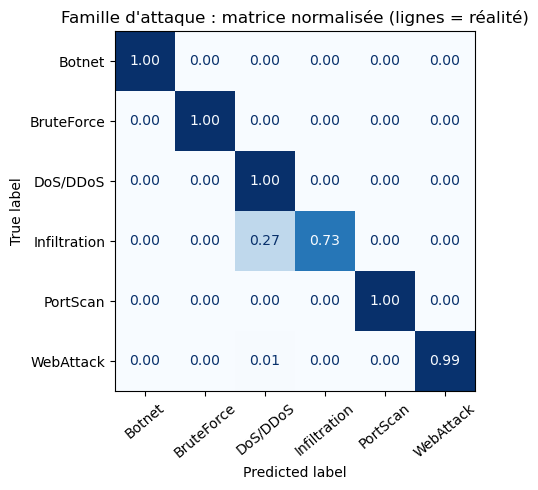

In [14]:
from sklearn.metrics import ConfusionMatrixDisplay
fig, ax = plt.subplots(figsize=(6.5, 5))
ConfusionMatrixDisplay.from_predictions(teF["family"], pF, normalize="true", xticks_rotation=40,
                                        values_format=".2f", cmap="Blues", ax=ax, colorbar=False)
ax.set_title("Famille d'attaque : matrice normalisée (lignes = réalité)")
plt.tight_layout(); plt.show()

### Chaîne complète et seuil de confiance
Sur les attaques réellement détectées par le modèle binaire (protocole A), le modèle multiclasse nomme-t-il la bonne famille ? Et que gagne-t-on à écarter les prédictions peu sûres ?

In [15]:
CONF_MIN = 0.60
m = (predsA["Random Forest"] == 1) & (teA.is_attack.to_numpy() == 1)
chain = teA[m]
proba = rfF.predict_proba(chain[FEATS].to_numpy("float32"))
fam_pred = rfF.classes_[proba.argmax(axis=1)]
conf = proba.max(axis=1)
ok = fam_pred == chain["family"].to_numpy()
print(f"Attaques détectées par l'étage 1 : {len(chain):,}")
print(f"Famille correcte (toutes)               : {ok.mean():.1%}")
print(f"Part avec confiance >= {CONF_MIN:.0%}             : {(conf >= CONF_MIN).mean():.1%}")
print(f"Famille correcte si confiance >= {CONF_MIN:.0%}   : {ok[conf >= CONF_MIN].mean():.1%}")
if (conf < CONF_MIN).any():
    print(f"Famille correcte si confiance <  {CONF_MIN:.0%}   : {ok[conf < CONF_MIN].mean():.1%}  <- à vérifier par un analyste")

Attaques détectées par l'étage 1 : 127,641
Famille correcte (toutes)               : 100.0%
Part avec confiance >= 60%             : 100.0%
Famille correcte si confiance >= 60%   : 100.0%
Famille correcte si confiance <  60%   : 35.7%  <- à vérifier par un analyste


### Sauvegarde du modèle de famille
On réentraîne sur **toutes** les attaques pour le modèle final de la démo.

In [16]:
import joblib
os.makedirs("../models", exist_ok=True)
allatt = pd.concat([g.sample(min(len(g), PER_CLASS_TRAIN_CAP or len(g)), random_state=SEED) for _, g in att.groupby("family")])
final_fam = RandomForestClassifier(n_estimators=200, class_weight="balanced_subsample", n_jobs=-1, random_state=SEED)
final_fam.fit(allatt[FEATS].to_numpy("float32"), allatt["family"])
joblib.dump({"model": final_fam, "features": FEATS, "classes": list(final_fam.classes_)}, "../models/ids_family_model.joblib")
print("Sauvegardé : ../models/ids_family_model.joblib | familles :", list(final_fam.classes_))

Sauvegardé : ../models/ids_family_model.joblib | familles : ['Botnet', 'BruteForce', 'DoS/DDoS', 'Infiltration', 'PortScan', 'WebAttack']


## 10. Sauvegarde du meilleur modèle (pour la démo Streamlit)

In [17]:
import joblib
os.makedirs("../models", exist_ok=True)
best = pd.DataFrame(resB).sort_values("f1", ascending=False).iloc[0].modele
print("Meilleur F1 en protocole B :", best)
if best != "Isolation Forest":
    joblib.dump({"model": modelsB[best], "features": FEATS}, "../models/ids_model.joblib")
    print("Sauvegardé : ../models/ids_model.joblib")
else:
    joblib.dump({"scaler_iso": modelsB[best], "features": FEATS}, "../models/ids_model.joblib")

Meilleur F1 en protocole B : Régression logistique
Sauvegardé : ../models/ids_model.joblib


## 11. Comment rédiger les résultats (chapitre 6)
1. **Présente A et B ensemble** et explique l'écart : « sur des attaques connues le modèle atteint X, sur des attaques inconnues Y ».
2. **Ne cite pas l'accuracy seule** : rappel, précision, F1, PR-AUC, faux positifs et faux négatifs.
3. **Analyse les erreurs** par type d'attaque (section 6) : lesquelles échappent, et pourquoi (nombre d'exemples, ressemblance avec le trafic normal).
4. **Discute `Destination Port`** (section 7) : preuve que tu as vérifié que le modèle ne triche pas.
5. **Compare avec tes règles** Wazuh/Sigma sur les mêmes flux : c'est ta problématique.
6. **Type d'attaque** : présente le modèle en **deux étages** (détection puis famille), son rapport de classification et le seuil de confiance « indéterminée ».
7. **Limites** : trafic généré en laboratoire en 2017, une seule semaine, peu d'attaques récentes.

### Pistes d'amélioration
- `GridSearchCV` / `RandomizedSearchCV` avec validation croisée **par jour** (`GroupKFold`)
- Autres jours de test (par exemple tester sur mercredi, entraîner sur le reste)
- Seuil de décision optimisé sur un jeu de validation
- Réseau de neurones simple (MLP) ou XGBoost/LightGBM
- Distinguer les attaques web entre elles (XSS, injection SQL) : trop peu d'exemples pour l'instant